PRACTICAL EXERCISE 4: SELF DRIVING AGENT

Members:

Sufi Hafswa Yusuf – 186400
Karani Shifla Wangui – 185318
Gitonga Collins Kinoti – 192560

## Part 1: Knowledge Base

The knowledge base stores towns, road connections and distances from Practical Exercise 3. Python dictionaries make the information easy to access and update.

**Vocabulary**
- **Town:** A location in the road network.
- **Road:** A directed connection between two towns.
- **Distance:** The length of a road in kilometres.
- **Connected:** Whether a direct road exists between two towns.
- **Road attributes:** Extra information such as speed limits and road conditions.

### Road Network

The network has 13 towns and 15 directed roads. The distances come from Practical Exercise 3.

In [ ]:
# Road distances in kilometres; each connection is directed.
graph = {
    "Nairobi": {"Ruiru": 24.6, "Naivasha": 91},
    "Ruiru": {"Thika": 21.4},
    "Thika": {"Nyeri": 113},
    "Nyeri": {"Nyahururu": 104},
    "Naivasha": {"Gilgil": 30.4},
    "Gilgil": {"Nyahururu": 67, "Nakuru": 42.6},
    "Nyahururu": {"Nakuru": 63.3},
    "Nakuru": {"Kericho": 107, "Eldoret": 156},
    "Kericho": {"Kisumu": 84},
    "Eldoret": {"Webuye": 71.6},
    "Webuye": {"Kakamega": 48.5},
    "Kakamega": {"Kisumu": 53.4},
    "Kisumu": {}
}

START = "Nairobi"
GOAL = "Kisumu"
towns = list(graph)
print("Towns:", len(towns))
print("Directed roads:", sum(map(len, graph.values())))

### Additional Road Information

Fields for road type, speed limit, road condition and fuel availability are included. Unverified values remain `None`.

In [ ]:
road_facts = {
    (origin, destination): {
        "distance_km": distance,
        "road_type": None,
        "speed_limit_kmh": None,
        "road_condition": None
    }
    for origin, neighbours in graph.items()
    for destination, distance in neighbours.items()
}

town_facts = {
    town: {"fuel_stop_available": None, "notes": ""}
    for town in towns
}

print("Road facts:", len(road_facts))
print("Town facts:", len(town_facts))

### Knowledge Base Functions

These functions retrieve connections and distances, check roads and add new road facts.

In [ ]:
def connected_towns(town):
    return graph.get(town, {}).copy()


def get_distance(start, end):
    return graph.get(start, {}).get(end)


def road_exists(start, end):
    return get_distance(start, end) is not None


def get_road_info(start, end):
    return road_facts.get((start, end))


def add_road(start, end, distance):
    if start not in graph or end not in graph:
        raise ValueError("Both towns must exist in the knowledge base.")
    if (not isinstance(distance, (int, float)) or isinstance(distance, bool)
            or not 0 < distance < float("inf")):
        raise ValueError("Distance must be a positive, finite number.")

    graph[start][end] = distance
    road_facts[(start, end)] = {
        "distance_km": distance,
        "road_type": None,
        "speed_limit_kmh": None,
        "road_condition": None
    }
    print(f"Road added: {start} -> {end} ({distance} km)")

print("Knowledge base functions ready.")

### Testing the Knowledge Base

The tests check the towns, roads, distances and lookup functions.

In [ ]:
assert len(graph) == 13
assert sum(len(neighbours) for neighbours in graph.values()) == 15

for origin, neighbours in graph.items():
    for destination, distance in neighbours.items():
        assert destination in graph
        assert distance > 0
        assert road_facts[(origin, destination)]["distance_km"] == distance

assert get_distance("Nairobi", "Naivasha") == 91
assert road_exists("Nairobi", "Ruiru")
assert not road_exists("Naivasha", "Nairobi")
assert connected_towns("Nairobi") == {"Ruiru": 24.6, "Naivasha": 91}
assert get_road_info("Nairobi", "Naivasha")["distance_km"] == 91

print("All knowledge-base tests passed.")

### Summary

The knowledge base stores 13 towns and 15 directed roads. It supports distance lookups, road checks and new facts. Member 2 can use `graph` for route calculations, while Member 3 can use the results in the user interface. Additional road details can be added when verified.

## Part 2: Reasoning and Inference — Member

### How the agent reasons

The agent uses **uniform-cost search** on the knowledge base. The path cost is the distance in kilometres, so the agent always expands the cheapest unexplored route first.

**Steps**
1. Check that the start and goal towns exist in the knowledge base.
2. Put the start town in the **frontier**, a priority queue ordered by total distance so far.
3. Remove the cheapest entry from the frontier.
4. If it is the goal, stop. The path found is the optimal one.
5. Otherwise, mark the town as explored and add each connected town to the frontier with its updated distance.
6. If the frontier becomes empty, no route exists.

**Why it finds the shortest route:** The frontier always releases the cheapest path first. When the goal is first removed, every other unfinished path already costs at least as much, so none of them can beat it. This only works because distances are never negative.

**Limitation:** All roads in the knowledge base are one-way (towards Kisumu), so some queries, such as Kisumu to Nairobi, have no route.

In [ ]:
import heapq


def find_optimal_route(start, goal):
    """Uniform-cost search using road distance (km) as the path cost.
    Returns (path, total_distance, message)."""
    for town in (start, goal):
        if town not in graph:
            return None, None, f"'{town}' is not in the knowledge base."

    frontier = [(0, start, [start])]   # (cost so far, town, path so far)
    explored = set()

    while frontier:
        cost, town, path = heapq.heappop(frontier)

        if town == goal:
            return path, round(cost, 1), "Route found."

        if town in explored:
            continue
        explored.add(town)

        for neighbour, distance in connected_towns(town).items():
            if neighbour not in explored:
                heapq.heappush(frontier, (cost + distance, neighbour, path + [neighbour]))

    return None, None, f"No route from {start} to {goal} exists in the knowledge base."


def explain_route(path, total):
    """Return a leg-by-leg explanation of the chosen route."""
    lines = [f"{a} -> {b}: {get_distance(a, b)} km" for a, b in zip(path, path[1:])]
    lines.append(f"Total distance: {total} km")
    return "\n".join(lines)


print("Reasoning functions ready.")

### Testing the reasoning

The tests check the optimal route against the Practical Exercise 3 answer, plus the edge cases: same start and goal, no route, and an unknown town.

In [ ]:
# Main case: Nairobi to Kisumu
path, total, message = find_optimal_route("Nairobi", "Kisumu")
print(explain_route(path, total))
assert path == ["Nairobi", "Naivasha", "Gilgil", "Nakuru", "Kericho", "Kisumu"]
assert total == 355.0

# Other routes
assert find_optimal_route("Nairobi", "Eldoret")[:2] == (["Nairobi", "Naivasha", "Gilgil", "Nakuru", "Eldoret"], 320.0)
assert find_optimal_route("Nairobi", "Nyahururu")[:2] == (["Nairobi", "Naivasha", "Gilgil", "Nyahururu"], 188.4)

# Edge cases
assert find_optimal_route("Nairobi", "Nairobi")[:2] == (["Nairobi"], 0)
assert find_optimal_route("Kisumu", "Nairobi")[0] is None        # one-way roads: no route
assert find_optimal_route("Nairobi", "Mombasa")[0] is None       # unknown town

print("\nAll reasoning tests passed.")

### Summary

The agent finds the shortest route between two towns using uniform-cost search over the knowledge base. It returns the path, total distance and a leg-by-leg explanation, and handles unknown towns and unreachable destinations with clear messages. Member 3 can call `find_optimal_route(start, goal)` and `explain_route(path, total)` from the user interface.

## Part 3: User Interaction — Member 3

### How the user interacts with the agent

The user chooses from a simple text menu. Each option calls the knowledge base or the reasoning function.
1. Route between 2 towns
2. Distance between 2 towns
3. Are 2 towns connected?
4. Which towns are connected to a town?
5. List all towns
6. Quit
   
Town names are not case sensitive. Unknown towns and missing routes give a clear message instead of an error.

### Answering questions

Each function returns the answer as text.

In [ ]:
def find_town(name):
    """Match what the user typed to a town in the knowledge base (ignores case)."""
    for town in graph:
        if town.lower() == name.strip().lower():
            return town
    return None


def answer_route(start, goal):
    path, total, message = find_optimal_route(start, goal)
    if path is None:
        return message
    return " -> ".join(path) + "\n" + explain_route(path, total)


def answer_distance(start, end):
    km = get_distance(start, end)
    if km is None:
        return f"There is no direct road from {start} to {end}."
    return f"{start} -> {end}: {km} km"


def answer_connections(town):
    roads = connected_towns(town)
    if not roads:
        return f"No roads leave {town}."
    return "\n".join(f"{town} -> {dest}: {km} km" for dest, km in roads.items())

def ask_town(prompt, input_fn):
    """Ask until a valid town is entered. Type 'list' to see towns or 'back' to cancel."""
    while True:
        text = input_fn(prompt).strip()
        if text.lower() == "back":
            return None
        if text.lower() == "list":
            print("Towns:", ", ".join(graph))
            continue
        town = find_town(text)
        if town:
            return town
        print("That town is not in the knowledge base. Type 'list' to see the towns or 'back' to return.")


def answer_connected(a, b):
    """Are two towns connected? Checks a direct road, then any route."""
    if a == b:
        return f"{a} and {b} are the same town."
    km = get_distance(a, b)
    if km is not None:
        return f"Yes. There is a direct road from {a} to {b} ({km} km)."
    path, total, _ = find_optimal_route(a, b)
    if path:
        return f"Yes, but not directly. Route: {' -> '.join(path)} ({total} km)."
    if find_optimal_route(b, a)[0]:
        return f"No route from {a} to {b}, but the roads do lead from {b} to {a}."
    return f"No. {a} and {b} are not connected."

print("Answer functions ready.")

### The menu

`run_agent()` shows the menu, reads the user's choice and prints the answer until the user quits.

In [ ]:
def run_agent(input_fn=input):
    while True:
        print("\n===== Trailer Route Assistant =====")
        print("1. Route between 2 towns")
        print("2. Distance between 2 towns")
        print("3. Are 2 towns connected?")
        print("4. Which towns are connected to a town?")
        print("5. List all towns")
        print("6. Quit")


        choice = input_fn("Choose an option: ").strip()

        if choice == "6":
            print("Goodbye!")
            break
        if choice == "5":
            print("Towns:", ", ".join(graph))
            continue
        if choice not in ("1", "2", "3", "4"):
            print("Please choose a number from 1 to 6.")
            continue

        first = ask_town("Enter the first town: " if choice != "4" else "Enter the town: ", input_fn)
        if first is None:
            continue
        if choice == "4":
            print(answer_connections(first))
            continue

        second = ask_town("Enter the second town: ", input_fn)
        if second is None:
            continue
        if choice == "1":
            print(answer_route(first, second))
        elif choice == "2":
            print(answer_distance(first, second))
        else:
            print(answer_connected(first, second))


print("Menu ready.")

### This provides a live option for the user

`LIVE_MODE = True` to accept user input at any time. It is `False` so that "Run all" does not wait for input.

In [ ]:
LIVE_MODE = True

if LIVE_MODE:
    run_agent()


===== Trailer Route Assistant =====
1. Route between 2 towns
2. Distance between 2 towns
3. Are 2 towns connected?
4. Which towns are connected to a town?
5. List all towns
6. Quit
Choose an option: 1
Enter the first town: Nakuru
Enter the second town: Eldoret
Nakuru -> Eldoret
Nakuru -> Eldoret: 156 km
Total distance: 156 km

===== Trailer Route Assistant =====
1. Route between 2 towns
2. Distance between 2 towns
3. Are 2 towns connected?
4. Which towns are connected to a town?
5. List all towns
6. Quit
Choose an option: 2
Enter the first town: Nairobi
Enter the second town: Kisumu
There is no direct road from Nairobi to Kisumu.

===== Trailer Route Assistant =====
1. Route between 2 towns
2. Distance between 2 towns
3. Are 2 towns connected?
4. Which towns are connected to a town?
5. List all towns
6. Quit
Choose an option: 5
Towns: Nairobi, Ruiru, Thika, Nyeri, Naivasha, Gilgil, Nyahururu, Nakuru, Kericho, Eldoret, Webuye, Kakamega, Kisumu

===== Trailer Route Assistant =====
1. Ro

# Evidence of team work

#
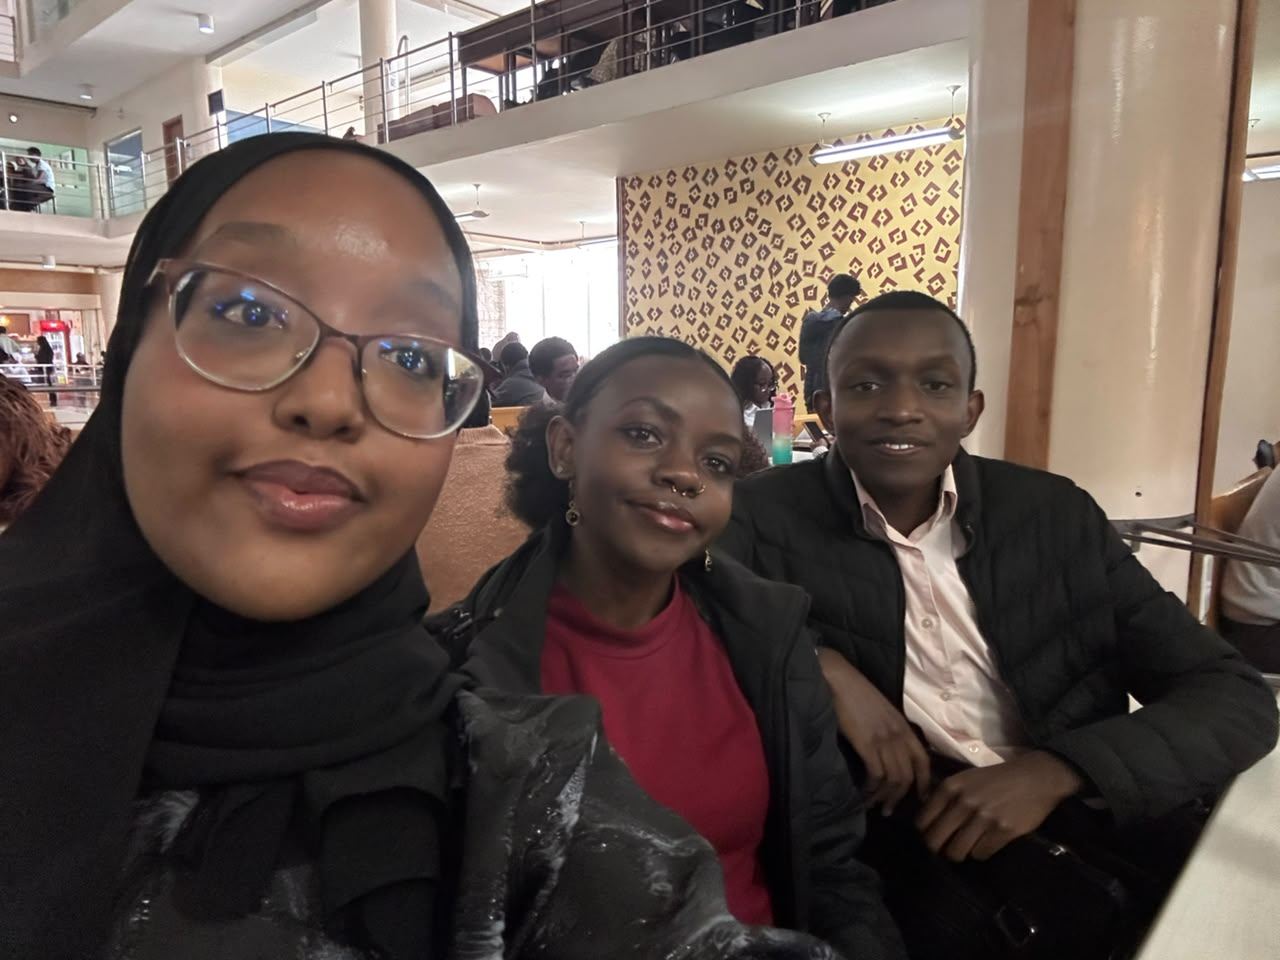